# Machine learning · Clasificación

k vecinos implementado a mano y con `scikit-learn`, regresión logística, árboles de decisión, métricas de clasificación y `Pipeline`. Se usan los conjuntos *iris*, *digits* y *wine* que trae `scikit-learn`.

## 1. El conjunto iris

Cargar *iris* como `DataFrame`, contar las flores de cada especie y dibujar el largo frente al ancho del pétalo coloreando por especie. Separar entrenamiento y prueba (70/30) manteniendo la proporción de especies (`stratify`).

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


{'setosa': 50, 'versicolor': 50, 'virginica': 50}


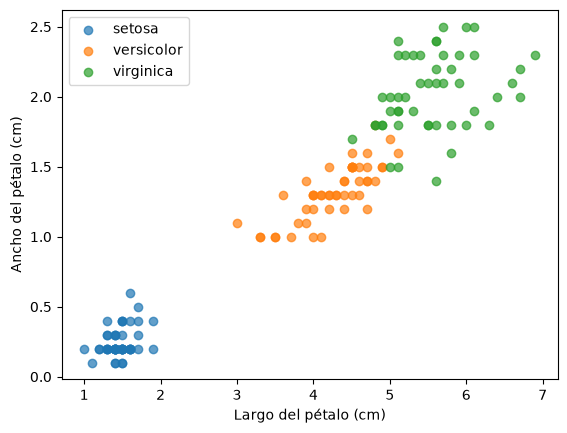

(105, 4) (45, 4) [15 15 15]


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
df = iris.frame
df["especie"] = iris.target_names[iris.target]
display(df.head())
print(df["especie"].value_counts().to_dict())

for especie, grupo in df.groupby("especie"):
    plt.scatter(grupo["petal length (cm)"], grupo["petal width (cm)"], label=especie, alpha=0.7)
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
plt.legend()
plt.show()

X, y = iris.data.to_numpy(), iris.target.to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=3)
print(X_train.shape, X_test.shape, np.bincount(y_test))

## 2. k vecinos a mano

Escribir `knn_predice(X_train, y_train, X, k)`, que clasifique cada punto de `X` con la clase más frecuente entre sus $k$ vecinos más cercanos (distancia euclídea), y calcular la exactitud (*accuracy*) en prueba con $k = 5$. Las distancias de todos los pares se calculan de una vez con *broadcasting*: coste $O(n\,m\,d)$.

In [2]:
def knn_predice(X_train, y_train, X, k=5):
    d2 = ((X[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=2)  # (m, n): distancias al cuadrado
    vecinos = np.argsort(d2, axis=1, kind="stable")[:, :k]
    return np.array([np.bincount(y_train[v]).argmax() for v in vecinos])

def exactitud(y, y_pred):
    return (y == y_pred).mean()

pred = knn_predice(X_train, y_train, X_test, k=5)
print("Exactitud con k = 5:", round(exactitud(y_test, pred), 3))
print("Errores (real, predicha):", [(str(iris.target_names[r]), str(iris.target_names[p])) for r, p in zip(y_test, pred) if r != p])

Exactitud con k = 5: 0.956
Errores (real, predicha): [('versicolor', 'virginica'), ('versicolor', 'virginica')]


## 3. `KNeighborsClassifier` y elección de $k$

Comprobar que `KNeighborsClassifier` da las mismas predicciones que la versión a mano para $k$ impar de 1 a 15 y dibujar la exactitud de entrenamiento y de prueba en función de $k$.

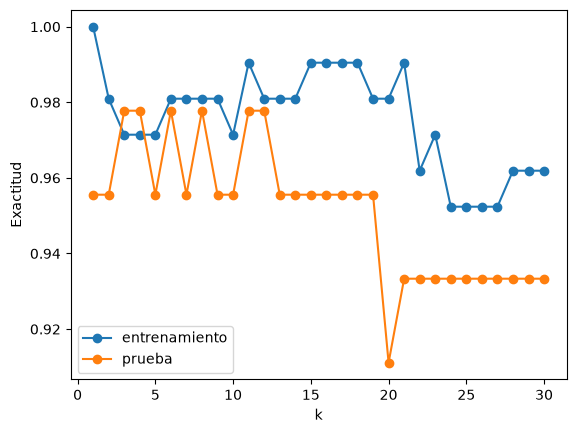

k con mejor exactitud de prueba: [3, 4, 6, 8, 11, 12]


In [3]:
from sklearn.neighbors import KNeighborsClassifier

ks = range(1, 31)
acc_train, acc_test = [], []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    acc_train.append(knn.score(X_train, y_train))
    acc_test.append(knn.score(X_test, y_test))
    if k % 2 and k <= 15:
        assert (knn.predict(X_test) == knn_predice(X_train, y_train, X_test, k)).all()

plt.plot(ks, acc_train, "o-", label="entrenamiento")
plt.plot(ks, acc_test, "o-", label="prueba")
plt.xlabel("k")
plt.ylabel("Exactitud")
plt.legend()
plt.show()
print("k con mejor exactitud de prueba:", [k for k, a in zip(ks, acc_test) if a == max(acc_test)])

## 4. Fronteras de decisión

Con solo el largo y el ancho del pétalo, dibujar las regiones de decisión de k vecinos con $k = 1$ y $k = 25$ usando `DecisionBoundaryDisplay`. Con $k = 1$ la frontera se adapta a cada punto; con $k$ grande es más suave.

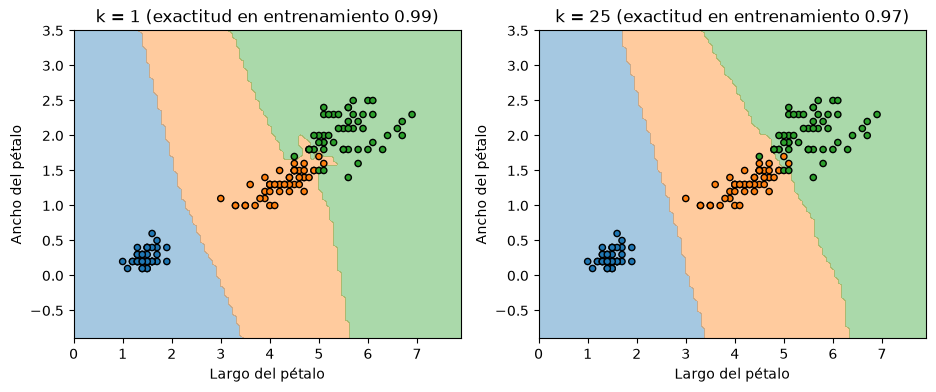

In [4]:
from sklearn.inspection import DecisionBoundaryDisplay

X2 = X[:, 2:]
colores = np.array(["tab:blue", "tab:orange", "tab:green"])
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(ejes, [1, 25]):
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(modelo, X2, ax=ax, alpha=0.4, multiclass_colors=list(colores), response_method="predict",
                                           xlabel="Largo del pétalo", ylabel="Ancho del pétalo")
    ax.scatter(X2[:, 0], X2[:, 1], c=colores[y], edgecolor="k", s=20)
    ax.set_title(f"k = {k} (exactitud en entrenamiento {modelo.score(X2, y):.2f})")
plt.show()

## 5. Regresión logística

La regresión logística estima la probabilidad de cada clase con la función sigmoide $\sigma(z) = \frac{1}{1 + e^{-z}}$ (o con *softmax* si hay más de dos clases):

$$P(y = c \mid x) = \frac{e^{z_c}}{\sum_j e^{z_j}}, \qquad z_c = w_c^\top x + b_c.$$

Dibujar la sigmoide, entrenar `LogisticRegression` con iris y comprobar a mano las probabilidades de `predict_proba` con `coef_` e `intercept_`.

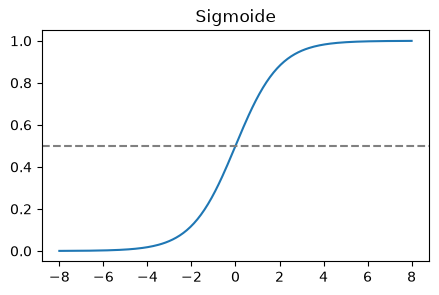

Exactitud de prueba: 0.933
[[0.984 0.016 0.   ]
 [0.    0.042 0.958]
 [0.979 0.021 0.   ]
 [0.024 0.895 0.082]
 [0.009 0.803 0.188]]


In [5]:
from sklearn.linear_model import LogisticRegression

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(5, 3))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="gray", linestyle="--")
plt.title("Sigmoide")
plt.show()

logistica = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print("Exactitud de prueba:", round(logistica.score(X_test, y_test), 3))

Z = X_test @ logistica.coef_.T + logistica.intercept_
probas = np.exp(Z) / np.exp(Z).sum(axis=1, keepdims=True)
print(np.round(probas[:5], 3))
assert np.allclose(probas, logistica.predict_proba(X_test))
assert (probas.argmax(axis=1) == logistica.predict(X_test)).all()

## 6. Árbol de decisión

Entrenar un `DecisionTreeClassifier` de profundidad máxima 3 con iris, dibujarlo con `plot_tree`, mostrar sus reglas con `export_text` y la importancia de cada variable. Comparar la exactitud de prueba para profundidades de 1 a 6.

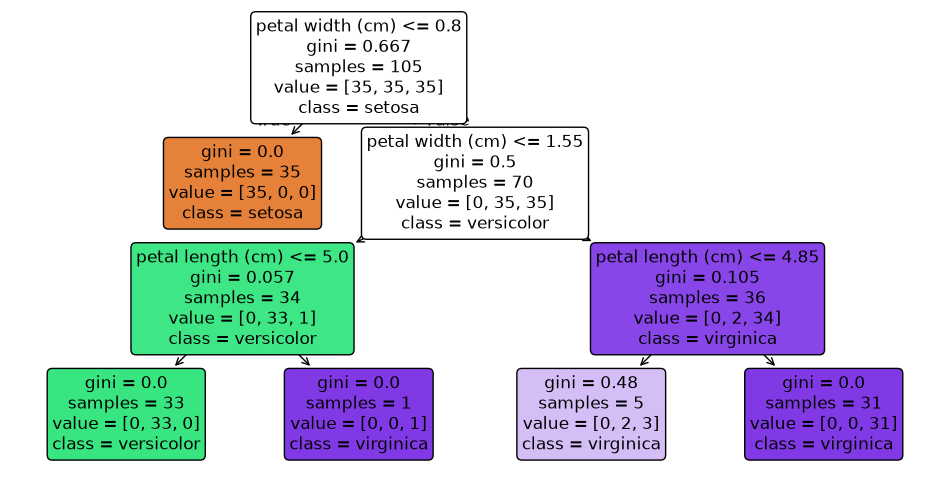

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 5.00
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  5.00
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2

{'sepal length (cm)': 0.0, 'sepal width (cm)': 0.0, 'petal length (cm)': 0.049, 'petal width (cm)': 0.951}
{1: 0.667, 2: 0.889, 3: 0.911, 4: 0.933, 5: 0.933, 6: 0.933}


In [6]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

arbol = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
plt.figure(figsize=(12, 6))
plot_tree(arbol, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=True, rounded=True)
plt.show()
print(export_text(arbol, feature_names=iris.feature_names))
print(dict(zip(iris.feature_names, arbol.feature_importances_.round(3).tolist())))
print({p: round(DecisionTreeClassifier(max_depth=p, random_state=0).fit(X_train, y_train).score(X_test, y_test), 3)
       for p in range(1, 7)})

## 7. Dígitos escritos a mano

Cargar *digits* (imágenes de 8 × 8 píxeles), mostrar algunas, clasificarlas con k vecinos ($k = 3$) y enseñar las imágenes de prueba mal clasificadas.

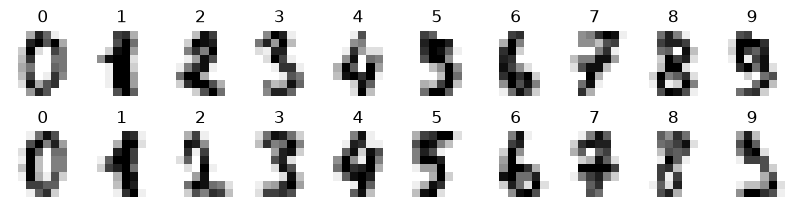

Exactitud: 0.985


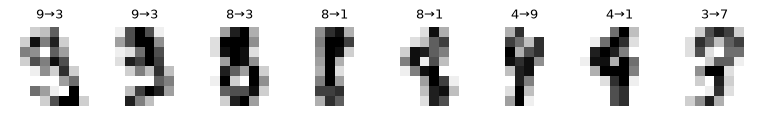

In [7]:
from sklearn.datasets import load_digits

digitos = load_digits()
fig, ejes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, imagen, etiqueta in zip(ejes.flat, digitos.images, digitos.target):
    ax.imshow(imagen, cmap="gray_r")
    ax.set_title(etiqueta)
    ax.axis("off")
plt.show()

Xd_train, Xd_test, yd_train, yd_test = train_test_split(digitos.data, digitos.target, test_size=0.3, stratify=digitos.target, random_state=0)
knn_d = KNeighborsClassifier(n_neighbors=3).fit(Xd_train, yd_train)
pred_d = knn_d.predict(Xd_test)
print("Exactitud:", round(exactitud(yd_test, pred_d), 3))
assert (pred_d == knn_predice(Xd_train, yd_train, Xd_test, 3)).all()

errores = np.flatnonzero(pred_d != yd_test)
fig, ejes = plt.subplots(1, len(errores), figsize=(1.2 * len(errores), 1.6))
for ax, i in zip(ejes, errores):
    ax.imshow(Xd_test[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"{yd_test[i]}→{pred_d[i]}", fontsize=9)
    ax.axis("off")
plt.show()

## 8. Matriz de confusión

Calcular a mano la matriz de confusión de los dígitos (fila: clase real, columna: clase predicha), compararla con `confusion_matrix` y dibujarla con `ConfusionMatrixDisplay`. ¿Qué dígitos se confunden más?

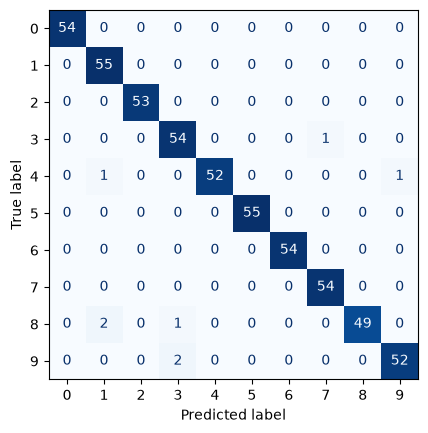

Confusión más frecuente: 8 tomado por 1 (2 veces)


In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

def matriz_confusion(y, y_pred, n_clases):
    m = np.zeros((n_clases, n_clases), dtype=int)
    np.add.at(m, (y, y_pred), 1)
    return m

M = matriz_confusion(yd_test, pred_d, 10)
assert (M == confusion_matrix(yd_test, pred_d)).all()

ConfusionMatrixDisplay(M).plot(cmap="Blues", colorbar=False)
plt.show()
fuera = M - np.diag(np.diag(M))
real, predicho = np.unravel_index(fuera.argmax(), M.shape)
print(f"Confusión más frecuente: {real} tomado por {predicho} ({fuera.max()} veces)")

## 9. Precisión, exhaustividad y F1

A partir de la matriz de confusión, calcular para cada clase

$$\text{precisión} = \frac{VP}{VP + FP}, \qquad \text{exhaustividad (recall)} = \frac{VP}{VP + FN}, \qquad F_1 = \frac{2\,P\,R}{P + R},$$

y sus medias (*macro*). Comprobarlo con `precision_recall_fscore_support` y mostrar el `classification_report`.

In [9]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

vp = np.diag(M)
precision = vp / M.sum(axis=0)
recall = vp / M.sum(axis=1)
f1 = 2 * precision * recall / (precision + recall)
print("Precisión:", precision.round(3))
print("Recall:   ", recall.round(3))
print(f"Macro: P = {precision.mean():.3f}  R = {recall.mean():.3f}  F1 = {f1.mean():.3f}")

p, r, f, soporte = precision_recall_fscore_support(yd_test, pred_d)
assert np.allclose(p, precision) and np.allclose(r, recall) and np.allclose(f, f1)
assert (soporte == M.sum(axis=1)).all()
print(classification_report(yd_test, pred_d, digits=3))

Precisión: [1.    0.948 1.    0.947 1.    1.    1.    0.982 1.    0.981]
Recall:    [1.    1.    1.    0.982 0.963 1.    1.    1.    0.942 0.963]
Macro: P = 0.986  R = 0.985  F1 = 0.985
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        54
           1      0.948     1.000     0.973        55
           2      1.000     1.000     1.000        53
           3      0.947     0.982     0.964        55
           4      1.000     0.963     0.981        54
           5      1.000     1.000     1.000        55
           6      1.000     1.000     1.000        54
           7      0.982     1.000     0.991        54
           8      1.000     0.942     0.970        52
           9      0.981     0.963     0.972        54

    accuracy                          0.985       540
   macro avg      0.986     0.985     0.985       540
weighted avg      0.986     0.985     0.985       540



## 10. `Pipeline` con escalado

En *wine* las variables tienen escalas muy distintas (la prolina llega a 1680 y otras no pasan de 1), y k vecinos depende de las distancias. Comparar k vecinos y regresión logística sin escalar y dentro de un `Pipeline` con `StandardScaler`, que ajusta el escalado solo con los datos de entrenamiento.

{'nonflavanoid_phenols': 0.66, 'hue': 1.71, 'ash': 3.23, 'proanthocyanins': 3.58, 'total_phenols': 3.88, 'od280/od315_of_diluted_wines': 4.0, 'flavanoids': 5.08, 'malic_acid': 5.8, 'color_intensity': 13.0, 'alcohol': 14.83, 'alcalinity_of_ash': 30.0, 'magnesium': 162.0, 'proline': 1680.0}


            k vecinos: 0.722
 k vecinos + escalado: 0.963
            logística: 0.963
 logística + escalado: 1.000


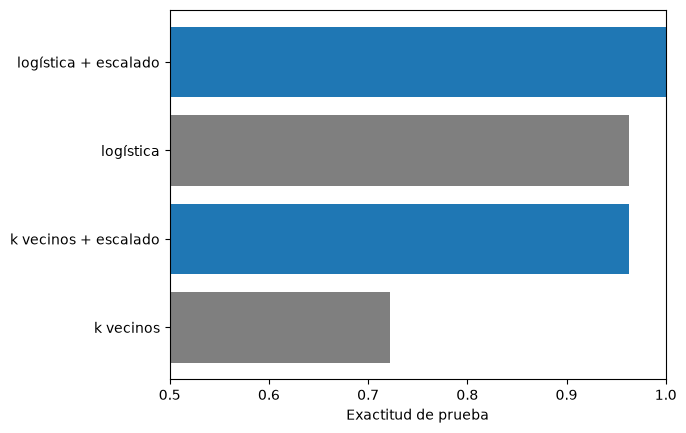

In [10]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

vino = load_wine()
print(pd.Series(vino.data.max(axis=0), index=vino.feature_names).round(2).sort_values().to_dict())
Xv_train, Xv_test, yv_train, yv_test = train_test_split(vino.data, vino.target, test_size=0.3, stratify=vino.target, random_state=0)

modelos = {
    "k vecinos": KNeighborsClassifier(),
    "k vecinos + escalado": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "logística": LogisticRegression(max_iter=10_000),
    "logística + escalado": make_pipeline(StandardScaler(), LogisticRegression()),
}
resultados = {nombre: m.fit(Xv_train, yv_train).score(Xv_test, yv_test) for nombre, m in modelos.items()}
for nombre, acc in resultados.items():
    print(f"{nombre:>21}: {acc:.3f}")

plt.barh(list(resultados), list(resultados.values()), color=["tab:gray", "tab:blue"] * 2)
plt.xlabel("Exactitud de prueba")
plt.xlim(0.5, 1)
plt.show()

escalado = modelos["k vecinos + escalado"]
assert np.allclose(escalado[0].mean_, Xv_train.mean(axis=0))
assert resultados["k vecinos + escalado"] > resultados["k vecinos"]